# Random Forest — Swindon Internal Model

This notebook uses a Random Forest regression model to predict LSOA-level GVA within Swindon.

The model is evaluated using five-fold GroupKFold cross-validation by MSOA. Feature importance represents predictive association, not causation.

In [2]:
from pathlib import Path
import warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score

warnings.filterwarnings("ignore")
OUTPUT_DIR = Path("../outputs/rf_swindon")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

features_path = Path("../data/features.csv")
names_path = Path("../data/Swindon LSOA local names.csv")

df_features = pd.read_csv(features_path)
df_names = pd.read_csv(names_path)

df_swindon = pd.merge(
    df_names[["LSOA21CD", "Local LSOA21 Name"]],
    df_features.drop_duplicates(subset=["LSOA21CD"], keep="first"),
    on="LSOA21CD",
    how="left"
)

print(df_swindon.shape)
display(df_swindon.head())

(140, 84)


,LSOA21CD,Local LSOA21 Name,LSOA21NM,LSOA21NMW,RUC21CD,RUC21NM,Urban_rura,Shape_Leng,Shape__Are,Shape__Len,...,share_enterprises_industrial_2025_msoa,share_enterprises_kibs_2025_msoa,share_enterprises_anchor_2025_msoa,enterprises_per_1k_residents_2025,share_enterprises_public_2025_msoa,share_enterprises_private_2025_msoa,bus_stop_count,area_km2,bus_stop_density,dist_to_primary_m
0,E01015471,Blunsdon St Andrew central,Swindon 028A,NaN,UN1,Urban: Nearer to a major town or city,Urban,4013.589687,5.013996e+05,4013.589687,...,0.020833,0.458333,0.083333,105.448155,0.000000,1.000000,5,1.298791,3.849735,617.714131
1,E01033861,Blunsdon St Andrew east,Swindon 028G,NaN,UN1,Urban: Nearer to a major town or city,Urban,4400.538691,6.930759e+05,4400.538691,...,0.020833,0.458333,0.083333,119.820270,0.000000,1.000000,8,1.795286,4.456115,353.783011
2,E01032710,Haydon east,Swindon 028E,NaN,UN1,Urban: Nearer to a major town or city,Urban,3300.845583,4.878420e+05,3300.845583,...,0.020833,0.458333,0.083333,171.184023,0.000000,1.000000,8,1.263367,6.332287,101.370297
3,E01033860,Groundwell,Swindon 028F,NaN,UN1,Urban: Nearer to a major town or city,Urban,3093.536938,4.921624e+05,3093.536938,...,0.020833,0.458333,0.083333,129.729730,0.000000,1.000000,3,1.274531,2.353807,193.498452
4,E01033843,"Broad Blunsdon, Castle Eaton and Hannington",Swindon 008H,NaN,UN1,Urban: Nearer to a major town or city,Urban,26225.609360,2.227618e+07,26225.609356,...,0.045752,0.405229,0.065359,529.778393,0.006536,0.993464,4,57.800596,0.069203,4781.724069


In [3]:
target = "LSOA GVA Estimates (millions)"

level4 = (
    "Level 4 qualifications or above: degree (BA, BSc), higher degree "
    "(MA, PhD, PGCE), NVQ level 4 to 5, HNC, HND, RSA Higher Diploma, "
    "BTEC Higher level, professional qualifications (for example, "
    "teaching, nursing, accountancy) %"
)

candidate_features = [
    "IMD_decile",
    "VOA_total_RV_pct_change",
    "employment_rate_per_pop",
    "LU_pct_micro_2025_msoa",
    "LU_pct_large_2025_msoa",
    "full_to_part_ratio",
    "LU_diversity_1-HHI_2025",
    "share_enterprises_green_aligned_2025_msoa",
    "share_enterprises_kibs_2025_msoa",
    "share_enterprises_creative_2025_msoa",
    "share_enterprises_industrial_2025_msoa",
    "share_enterprises_foundational_2025_msoa",
    "No qualifications %",
    level4,
    "Average download speed (Mbit/s)",
    "bus_stop_density",
    "enterprises_per_1k_residents_2025",
    "dist_to_primary_m"
]

features = [c for c in candidate_features if c in df_swindon.columns]
model_df = df_swindon.dropna(subset=[target, "MSOA21CD"]).copy()

X = model_df[features].replace([np.inf, -np.inf], np.nan)
y = model_df[target].astype(float)
groups = model_df["MSOA21CD"]

print("Rows:", len(model_df))
print("MSOA groups:", groups.nunique())
print("Features:", len(features))
print(features)

Rows: 127
MSOA groups: 27
Features: 18
['IMD_decile', 'VOA_total_RV_pct_change', 'employment_rate_per_pop', 'LU_pct_micro_2025_msoa', 'LU_pct_large_2025_msoa', 'full_to_part_ratio', 'LU_diversity_1-HHI_2025', 'share_enterprises_green_aligned_2025_msoa', 'share_enterprises_kibs_2025_msoa', 'share_enterprises_creative_2025_msoa', 'share_enterprises_industrial_2025_msoa', 'share_enterprises_foundational_2025_msoa', 'No qualifications %', 'Level 4 qualifications or above: degree (BA, BSc), higher degree (MA, PhD, PGCE), NVQ level 4 to 5, HNC, HND, RSA Higher Diploma, BTEC Higher level, professional qualifications (for example, teaching, nursing, accountancy) %', 'Average download speed (Mbit/s)', 'bus_stop_density', 'enterprises_per_1k_residents_2025', 'dist_to_primary_m']


In [4]:
def make_model():
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestRegressor(
            n_estimators=300,
            max_depth=6,
            min_samples_split=5,
            min_samples_leaf=2,
            max_features=0.8,
            bootstrap=True,
            random_state=42,
            n_jobs=1
        ))
    ])

    return TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1,
        check_inverse=False
    )

cv = GroupKFold(n_splits=5)
oof = pd.Series(index=X.index, dtype=float)
fold_rows = []
importance_arrays = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups), start=1):
    model = make_model()
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    pred = model.predict(X.iloc[test_idx])
    oof.loc[X.index[test_idx]] = pred

    fold_rows.append({
        "Fold": fold,
        "MAE": mean_absolute_error(y.iloc[test_idx], pred),
        "MedianAE": median_absolute_error(y.iloc[test_idx], pred),
        "RMSE": np.sqrt(mean_squared_error(y.iloc[test_idx], pred)),
        "R2": r2_score(y.iloc[test_idx], pred)
    })

    p = permutation_importance(
        model,
        X.iloc[test_idx],
        y.iloc[test_idx],
        n_repeats=5,
        random_state=42 + fold,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )
    importance_arrays.append(p.importances_mean)

fold_metrics = pd.DataFrame(fold_rows)
display(fold_metrics.round(3))

,Fold,MAE,MedianAE,RMSE,R2
0,1,13.305,4.640,22.873,0.493
1,2,47.830,13.821,98.881,0.361
2,3,187.356,6.984,621.198,0.064
3,4,31.530,3.351,72.635,-0.403
4,5,33.371,4.918,107.723,0.397


In [5]:
largest_idx = y.idxmax()
largest_name = model_df.loc[largest_idx, "Local LSOA21 Name"]
without_largest = y.index != largest_idx

overall_metrics = pd.DataFrame([
    {
        "Sample": "All observed Swindon LSOAs",
        "N": len(y),
        "MAE": mean_absolute_error(y, oof),
        "MedianAE": median_absolute_error(y, oof),
        "RMSE": np.sqrt(mean_squared_error(y, oof)),
        "R2": r2_score(y, oof)
    },
    {
        "Sample": f"Without largest GVA outlier ({largest_name})",
        "N": int(without_largest.sum()),
        "MAE": mean_absolute_error(y[without_largest], oof[without_largest]),
        "MedianAE": median_absolute_error(y[without_largest], oof[without_largest]),
        "RMSE": np.sqrt(mean_squared_error(y[without_largest], oof[without_largest])),
        "R2": r2_score(y[without_largest], oof[without_largest])
    }
])

importance_df = pd.DataFrame({
    "Feature": features,
    "Mean_permutation_importance": np.mean(importance_arrays, axis=0),
    "Between_fold_SD": np.std(importance_arrays, axis=0)
}).sort_values("Mean_permutation_importance", ascending=False)

predictions = model_df[
    ["LSOA21CD", "MSOA21CD", "Local LSOA21 Name"]
].copy()
predictions["Actual_GVA"] = y
predictions["Predicted_GVA"] = oof
predictions["Residual"] = y - oof
predictions["Absolute_error"] = predictions["Residual"].abs()

display(overall_metrics.round(3))
display(importance_df.head(15).round(3))
display(predictions.nlargest(10, "Absolute_error").round(3))

,Sample,N,MAE,MedianAE,RMSE,R2
0,All observed Swindon LSOAs,127,64.884,5.243,295.653,0.143
1,Without largest GVA outlier (Freshbrook south),126,40.388,5.230,96.370,0.369


,Feature,Mean_permutation_importance,Between_fold_SD
2,employment_rate_per_pop,28.046,14.208
6,LU_diversity_1-HHI_2025,0.802,6.217
0,IMD_decile,0.381,0.550
11,share_enterprises_foundational_2025_msoa,0.276,0.537
14,Average download speed (Mbit/s),0.102,0.333
17,dist_to_primary_m,0.089,0.478
15,bus_stop_density,0.074,0.229
13,"Level 4 qualifications or above: degree (BA, B...",-0.014,1.318
8,share_enterprises_kibs_2025_msoa,-0.022,0.152
9,share_enterprises_creative_2025_msoa,-0.039,0.114


,LSOA21CD,MSOA21CD,Local LSOA21 Name,Actual_GVA,Predicted_GVA,Residual,Absolute_error
79,E01015503,E02003233,Freshbrook south,3412.047,260.702,3151.345,3151.345
35,E01015509,E02003221,Pinehurst south east,706.386,191.295,515.091,515.091
68,E01015551,E02003220,Stratton St Margaret,457.800,52.925,404.875,404.875
67,E01015549,E02003220,Lower Stratton south west,457.800,83.591,374.209,374.209
109,E01015535,E02003235,Lawn central,354.575,19.046,335.529,335.529
49,E01015568,E02003225,Westlea,520.949,209.558,311.391,311.391
59,E01015582,E02003223,Rodbourne south east,104.261,353.628,-249.367,249.367
44,E01015548,E02003219,Ridgeway north east,316.009,70.306,245.703,245.703
5,E01015473,E02003219,Stanton Fitzwarren,495.260,269.715,225.545,225.545
114,E01015581,E02003223,Rodbourne west,222.950,411.285,-188.335,188.335


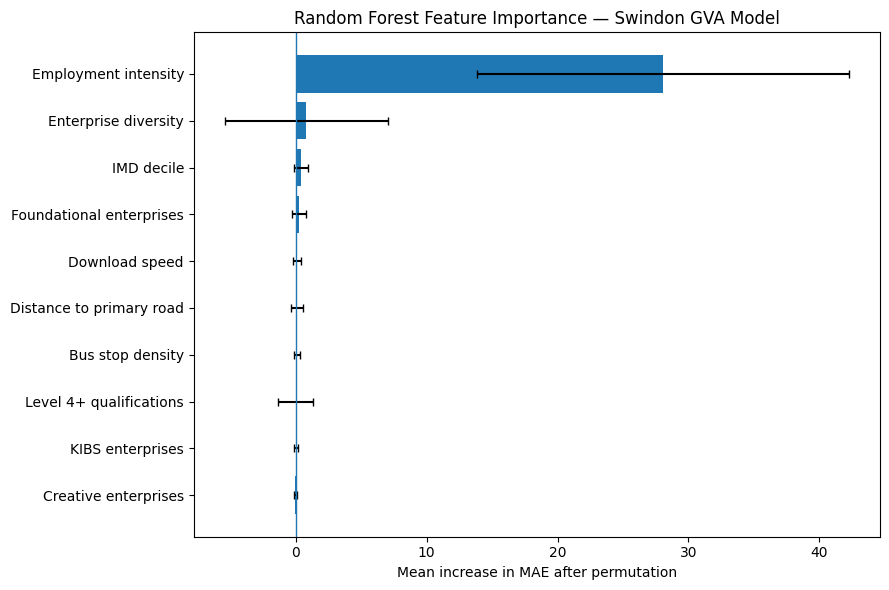

In [6]:
short_names = {
    "employment_rate_per_pop": "Employment intensity",
    "LU_diversity_1-HHI_2025": "Enterprise diversity",
    "IMD_decile": "IMD decile",
    "share_enterprises_foundational_2025_msoa": "Foundational enterprises",
    "Average download speed (Mbit/s)": "Download speed",
    "dist_to_primary_m": "Distance to primary road",
    "bus_stop_density": "Bus stop density",
    "Level 4 qualifications or above: degree (BA, BSc), higher degree (MA, PhD, PGCE), NVQ level 4 to 5, HNC, HND, RSA Higher Diploma, BTEC Higher level, professional qualifications (for example, teaching, nursing, accountancy) %": "Level 4+ qualifications",
    "share_enterprises_kibs_2025_msoa": "KIBS enterprises",
    "share_enterprises_creative_2025_msoa": "Creative enterprises",
    "full_to_part_ratio": "Full-time / part-time ratio",
    "No qualifications %": "No qualifications",
    "share_enterprises_industrial_2025_msoa": "Industrial enterprises",
    "LU_pct_micro_2025_msoa": "Micro enterprises",
    "LU_pct_large_2025_msoa": "Large enterprises"
}

plot_data = importance_df.copy()
plot_data["Display_name"] = plot_data["Feature"].replace(short_names)

plot_data = (
    plot_data
    .sort_values("Mean_permutation_importance", ascending=False)
    .head(10)
    .sort_values("Mean_permutation_importance")
)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_data["Display_name"],
    plot_data["Mean_permutation_importance"],
    xerr=plot_data["Between_fold_SD"].fillna(0),
    capsize=3
)

plt.axvline(0, linewidth=1)
plt.xlabel("Mean increase in MAE after permutation")
plt.ylabel("")
plt.title("Random Forest Feature Importance — Swindon GVA Model")
plt.tight_layout()

plt.savefig(
    "rf_swindon_feature_importance_improved.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
# Save results
fold_metrics.to_csv(OUTPUT_DIR / "rf_swindon_cv_metrics_by_fold.csv", index=False)
overall_metrics.to_csv(OUTPUT_DIR / "rf_swindon_overall_metrics.csv", index=False)
importance_df.to_csv(OUTPUT_DIR / "rf_swindon_permutation_importance.csv", index=False)
predictions.to_csv(OUTPUT_DIR / "rf_swindon_oof_predictions.csv", index=False)

final_model = make_model()
final_model.fit(X, y)

joblib.dump(
    {
        "model": final_model,
        "features": features,
        "target": target,
        "group_variable": "MSOA21CD"
    },
    OUTPUT_DIR / "rf_swindon_gva_model.joblib"
)

print("Saved to:", OUTPUT_DIR.resolve())

Saved to: ../outputs/rf_swindon


## Ablation: how much of the model is employment intensity alone?

`employment_rate_per_pop` has a permutation importance roughly 40 times larger than the next-highest feature (23.901 vs. 0.565; see previous cell). This motivates a direct ablation check: how much of the model's cross-validated predictive performance comes from this single variable, compared with the full model and a model in which it is excluded?

The same Random Forest pipeline (`make_model()`) is re-run on three predictor sets using the same five-fold `GroupKFold` splits by MSOA for all three. The splits are computed once below and reused, ensuring that the resulting scores are directly comparable. \(R^2\) is measured on the log1p(GVA) scale, using `log1p(actual)` and `log1p(predicted)`, because this is the scale on which the model is fitted; the target is transformed with `log1p` and predictions are inverse-transformed with `expm1` inside `make_model()`, rather than using plain `log(GVA)`.

1. Employment intensity alone
2. All 18 predictors
3. All predictors except employment intensity (17 variables)

In [8]:
EMP = "employment_rate_per_pop"

ABLATION_SPLITS = list(GroupKFold(n_splits=5).split(model_df, y, groups))

def r2_log_cv(feature_list, splits=ABLATION_SPLITS):

    Xf = model_df[feature_list].replace([np.inf, -np.inf], np.nan)
    oof_ablation = pd.Series(index=Xf.index, dtype=float)
    for train_idx, test_idx in splits:
        m = make_model()
        m.fit(Xf.iloc[train_idx], y.iloc[train_idx])
        oof_ablation.iloc[test_idx] = m.predict(Xf.iloc[test_idx])
    return r2_score(np.log1p(y), np.log1p(oof_ablation.clip(lower=0)))

ablation_sets = {
    "Employment intensity alone": [EMP],
    "All 18 predictors": features,
    "All 18 except employment intensity": [f for f in features if f != EMP],
}

ablation_df = pd.DataFrame({
    "Predictor set": list(ablation_sets.keys()),
    "N predictors": [len(v) for v in ablation_sets.values()],
    "R2_log1p": [r2_log_cv(v) for v in ablation_sets.values()],
})

display(ablation_df.round(3))

a, b, c = ablation_df["R2_log1p"]
print(f"\nThe other 17 predictors add {b - a:+.3f} to R2_log1p ({a:.3f} -> {b:.3f}).")
print(f"Removing employment intensity costs {c - b:+.3f} to R2_log1p ({b:.3f} -> {c:.3f}).")

,Predictor set,N predictors,R2_log1p
0,Employment intensity alone,1,0.699
1,All 18 predictors,18,0.727
2,All 18 except employment intensity,17,0.445



The other 17 predictors add +0.029 to R2_log1p (0.699 -> 0.727).
Removing employment intensity costs -0.283 to R2_log1p (0.727 -> 0.445).


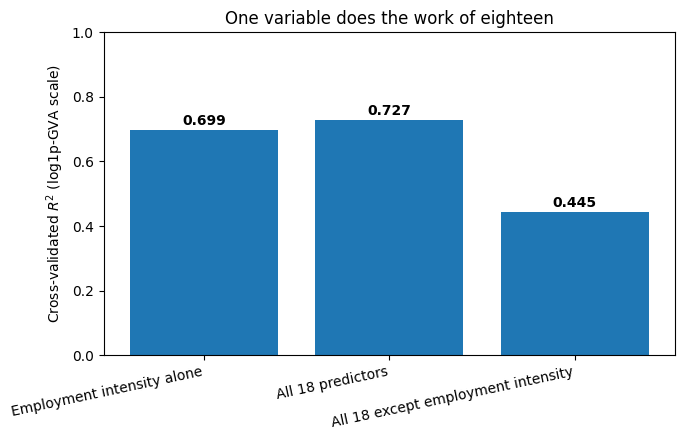

Saved to: ../outputs/rf_swindon/rf_swindon_ablation.csv


In [9]:
plt.figure(figsize=(7, 4.5))
bars = plt.bar(ablation_df["Predictor set"], ablation_df["R2_log1p"])
for x, v in enumerate(ablation_df["R2_log1p"]):
    plt.text(x, v + 0.015, f"{v:.3f}", ha="center", fontweight="bold")

plt.ylabel("Cross-validated $R^2$ (log1p-GVA scale)")
plt.ylim(0, 1.0)
plt.title("One variable does the work of eighteen")
plt.xticks(rotation=12, ha="right")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "rf_swindon_ablation.png", dpi=300, bbox_inches="tight")
ablation_df.to_csv(OUTPUT_DIR / "rf_swindon_ablation.csv", index=False)
plt.show()

print("Saved to:", (OUTPUT_DIR / "rf_swindon_ablation.csv").resolve())